# 02 Baselines: how good is "same as last week"?

**The forecasting set-up for the whole project**

- **Horizon:** every Monday-to-Sunday style week, forecast the next **168 hours** (7 days) from the end of the previous day.
- **Test period:** the last 52 weeks of data, 7 October 2025 to 5 October 2026. Each week is forecast using only data from before it (**walk-forward**). Nothing is ever shuffled: in time series, a random split lets the model peek at the future.
- **Error measures:** **MAPE** (mean absolute percentage error, easy for managers) and **MAE** in MW (the size of the error the control room has to cover).

Two baselines a forecaster would always try first:

1. **Seasonal naive:** each hour next week = the same hour this week.
2. **Four-week average:** each hour next week = the average of the same hour over the last four weeks.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd

hourly = pd.read_parquet("../data/processed/hourly.parquet")
y = hourly["demand"]
TEST_START = pd.Timestamp("2025-10-07")
origins = pd.date_range(TEST_START, periods=52, freq="7D")
print(f"Test weeks: {origins[0].date()} to {(origins[-1] + pd.Timedelta(days=6)).date()}")

Test weeks: 2025-10-07 to 2026-10-05


In [2]:
naive = y.shift(168)
four_week = sum(y.shift(168 * k) for k in range(1, 5)) / 4

test_index = pd.date_range(TEST_START, origins[-1] + pd.Timedelta(hours=167), freq="h")
results = pd.DataFrame({"actual": y.loc[test_index], "seasonal_naive": naive.loc[test_index],
                        "four_week_average": four_week.loc[test_index],
                        "eskom_published": hourly["eskom_forecast"].loc[test_index]})

def scores(frame, cols):
    out = {}
    for c in cols:
        err = frame[c] - frame.actual
        out[c] = {"MAPE (%)": (err.abs() / frame.actual).mean() * 100, "MAE (MW)": err.abs().mean(),
                  "bias (MW)": err.mean()}
    return pd.DataFrame(out).T.round(2)

scores(results, ["seasonal_naive", "four_week_average"])

,MAPE (%),MAE (MW),bias (MW)
seasonal_naive,3.64,817.98,15.02
four_week_average,3.70,826.43,57.14


Both baselines only use information from at least a week earlier, so they are honest week-ahead forecasts. The seasonal naive is already within about 4% on average, because the daily and weekly cycles repeat strongly. Its weaknesses are predictable: it copies last week's public holiday into this week, misses this week's holiday, and lags behind seasonal turns into and out of winter. The four-week average smooths out one-off weeks but trails a falling trend.

These numbers are the bar every model in Step 5 has to clear.

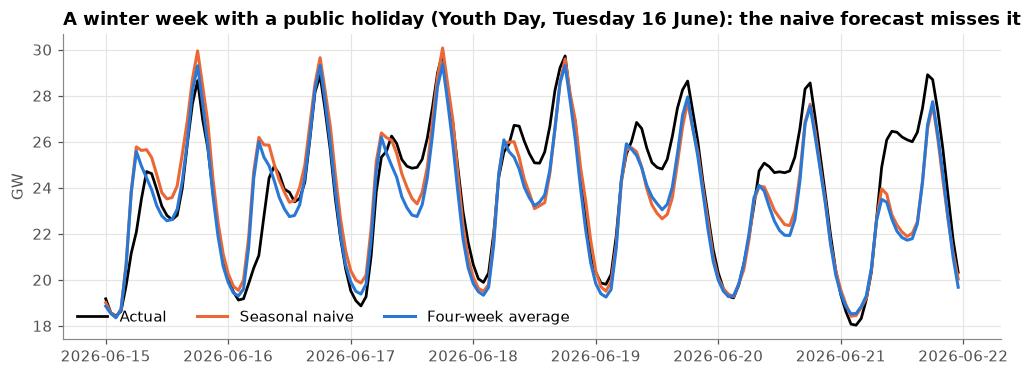

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
wk = results.loc["2026-06-15":"2026-06-21 23:00"]
ax.plot(wk.index, wk.actual / 1000, color="black", linewidth=1.8, label="Actual")
ax.plot(wk.index, wk.seasonal_naive / 1000, color=ORANGE, label="Seasonal naive")
ax.plot(wk.index, wk.four_week_average / 1000, color=BLUE, label="Four-week average")
ax.set_ylabel("GW"); ax.legend(ncol=3, loc="lower left")
ax.set_title("A winter week with a public holiday (Youth Day, Tuesday 16 June): the naive forecast misses it")
fig.savefig("../figures/baselines_example_week.png")
plt.show()

In [4]:
results.to_parquet("../data/processed/baseline_forecasts.parquet")